# Standardized sorghum leaf segmentation and ExG disease index — single-image CPU reproduction

**Paper:** Davis, Turkus, Arora, ... Schnable et al., *Embeddings from standardized sorghum leaf images capture variation in disease response that human scoring misses*, bioRxiv v1 (2026-09-22), DOI [10.64898/2026.09.21.753202](https://doi.org/10.64898/2026.09.21.753202).

**Author code:** [`jschnable/SorghumLeafEmbeddings`](https://github.com/jschnable/SorghumLeafEmbeddings) @ commit `4d859d1bdc45b03a3552c4198e998fcab9cd0a2f` (CC BY 4.0).

**Scope (partial demonstration).** The paper's full pipeline (SAM3/DINOv2 embeddings → random forests → embedding GWAS) needs raw image collections, a 925-genotype marker VCF, expression data, and gated model checkpoints that are not publicly retrievable. This notebook instead reproduces the paper's **documented single-image CPU quick start**: Methods 4.4 segmentation of one author-provided chamber photograph into a transparent leaf mask, plus the Methods 4.6 ExG unhealthy-tissue measurement with the paper's calibrated threshold (−0.0303).

**Execution status:** all code below is the authors' pinned implementation; the executed example and checks are validated on Colab CPU.

**スコープ（部分再現）:** 本論文の完全パイプライン（SAM3/DINOv2 埋め込み → ランダムフォレスト → 埋め込み GWAS）には未公開の画像collection・VCF・発現データ・ゲート付きチェックポイントが必要なため、著者提供のサンプル画像 1 枚に対する Methods 4.4 のセグメンテーション（CPU クイックスタート）と Methods 4.6 の ExG 食品評価を再現します。

**What runs here (paper → notebook mapping)**

| Paper operation | Author source (commit `4d859d1b`) | Notebook cell |
|---|---|---|
| Leaf segmentation (flood-fill from 2 seeds, largest side-touching component, edge trims, color-card rejection) | `scripts/segment_leaf.py::process_array` | Run author quick-start |
| Mask validity 750,000–7,500,000 px | `scripts/prepare_illustrations.py` main(); `make_exg_overlays.py` | Run author quick-start |
| Transparent leaf PNG + `preparation.json` manifest | `scripts/prepare_illustrations.py --mode leaf` | Run author quick-start |
| Normalized ExG = 2g−r−b, threshold −0.0303, blue disease overlay | `figures/supplemental/FigS1_human_vi_workflows/make_exg_overlays.py::calculate_exg` and main() | ExG cells |

**Out of scope:** embedding extraction (SAM3 checkpoint is gated; DINOv2 crops), random forests, GWAS/hotspots, crop generation, the scoring web app. This is **not** a verification of any published dataset-level result.

## Runtime: CPU only

This demonstration uses only OpenCV flood fills and connected components on one ~2 MB JPEG. **Select Runtime → Change runtime type → CPU** (a GPU is unnecessary; the notebook detects and reports whatever you have). No credentials or Drive mount are needed.

**Run all:** Runtime → Run all. Expected total time is a few minutes on the free CPU tier; downloads total ≈ 2 MB (three small author-code files + one example image).

**ランタイム:** CPU のみで動作します（GPU 不要）。「ランタイム → すべてのセルを実行」で数分で完了し、ダウンロードは合計約 2 MB です。

In [ ]:
import importlib.util, subprocess, sys

if importlib.util.find_spec("cv2") is None:
    # The authors pin opencv-python==4.6.0.66 (Python <=3.10 wheels only);
    # on Colab's newer Python we use the preinstalled OpenCV if present.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"])

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import PIL
import sklearn
import pandas as pd

print("python", sys.version.split()[0])
for mod in (cv2, np, sklearn, matplotlib, PIL, pd):
    print(mod.__name__, getattr(mod, "__version__", "?"))

python 3.13.16
cv2 4.14.0
numpy 2.1.3
sklearn 1.6.1
matplotlib 3.10.0
PIL 11.3.0
pandas 2.2.3


### Input provenance — pinned author files

**English:** We fetch the authors' exact pinned files (commit `4d859d1...`) into a small replica of the repository layout under `/content`, and verify each download against its Git blob SHA-1 from the pinned commit's tree. The example photograph is the exact one named in the authors' `scripts/README.md` quick start. Nothing is executed from these files yet.

**日本語:** 著者のコミット `4d859d1...` からコード 3 ファイルとサンプル画像 1 枚を取得し、Git blob SHA-1 で一致を検証します。画像は `scripts/README.md` のクイックスタートが指定するものと同一です。

In [ ]:
import hashlib
from pathlib import Path
import urllib.request

COMMIT = "4d859d1bdc45b03a3552c4198e998fcab9cd0a2f"
RAW = "https://raw.githubusercontent.com/jschnable/SorghumLeafEmbeddings/4d859d1bdc45b03a3552c4198e998fcab9cd0a2f"
REPO_ROOT = Path("/content/SorghumLeafEmbeddings")

def git_blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

# (repo-relative path, expected Git blob SHA-1 from the pinned commit tree)
CODE_FILES = [
    ("scripts/segment_leaf.py", "01eadf34317f9b9e33b7cad1b6627c9c68bb5b42"),
    ("scripts/prepare_illustrations.py", "21dda3c273847c256a155506587fa0dc56dee1e4"),
    ("figures/supplemental/FigS1_human_vi_workflows/make_exg_overlays.py",
     "f5b8b5f363138a4fd9364c33f31f6e313531ee29"),
]

for rel, expected in CODE_FILES:
    dest = REPO_ROOT / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    data = urllib.request.urlopen(f"{RAW}/{urllib.request.quote(rel)}", timeout=120).read()
    assert git_blob_sha1(data) == expected, f"blob SHA-1 mismatch: {rel}"
    dest.write_bytes(data)
    print(f"OK {rel}: {len(data)} bytes, blob sha1 {expected[:12]}…")

OK scripts/segment_leaf.py: 8625 bytes, blob sha1 01eadf34317f…
OK scripts/prepare_illustrations.py: 8128 bytes, blob sha1 21dda3c27384…


OK figures/supplemental/FigS1_human_vi_workflows/make_exg_overlays.py: 6001 bytes, blob sha1 f5b8b5f36313…


### Example image — the exact quick-start sample

**English:** We fetch the single example photograph named in the authors' quick start (`1064_LeafPhotoA_2025-09-08 12_56_11.568-05_00.jpg`) from the pinned commit and verify its byte size (1,984,122), Git blob SHA-1, and that it decodes as a 3-channel image. This is dataset content, so it is downloaded and inspected here in Colab only.

**日本語:** クイックスタートで指定されたサンプル画像 1 枚のみを取得し、サイズ・blob SHA-1・デコードを検証します。

In [ ]:
IMG_NAME = "1064_LeafPhotoA_2025-09-08 12_56_11.568-05_00.jpg"
IMG_SHA = "4373b827aae093f943f7df9171f75e1b4515f6e9"
IMG_BYTES = 1984122
img_path = REPO_ROOT / "data/provided/examples/images" / IMG_NAME
img_path.parent.mkdir(parents=True, exist_ok=True)

data = urllib.request.urlopen(f"{RAW}/data/provided/examples/images/1064_LeafPhotoA_2025-09-08%2012_56_11.568-05_00.jpg", timeout=300).read()
assert len(data) == IMG_BYTES, f"unexpected size {len(data)}"
assert git_blob_sha1(data) == IMG_SHA, "blob SHA-1 mismatch"
img_path.write_bytes(data)

import cv2
probe = cv2.imread(str(img_path))
assert probe is not None, "downloaded file does not decode as an image"
print(f"OK {IMG_NAME}: {len(data)} bytes, blob sha1 verified, decodes as {probe.shape} BGR")

OK 1064_LeafPhotoA_2025-09-08 12_56_11.568-05_00.jpg: 1984122 bytes, blob sha1 verified, decodes as (4080, 3060, 3) BGR


### Input preview

**English:** We display the downloaded chamber photograph (Methods 4.2–4.3 standardized setup: white PLA chamber, LED lighting, color card in the upper right). The image is 3060×4080 px as captured by the phone camera; dimensions are printed from the actual file.

**日本語:** ダウンロードした撮影 chamber の写真を表示します（寸法は実ファイルから表示）。

image shape (H, W, C): (4080, 3060, 3)


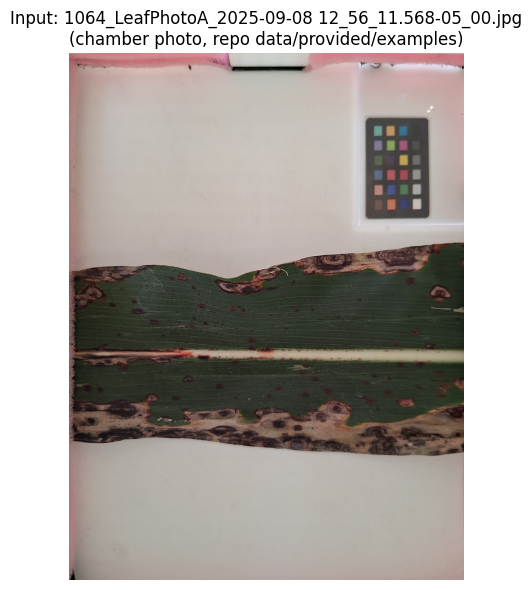

In [ ]:
rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
print("image shape (H, W, C):", rgb.shape)

fig, ax = plt.subplots(figsize=(4.5, 6))
ax.imshow(rgb)
ax.set_title(f"Input: {IMG_NAME}\n(chamber photo, repo data/provided/examples)")
ax.axis("off")
plt.tight_layout()
plt.savefig("/content/input_photo.png", dpi=120, bbox_inches="tight")
plt.show()

### Run the authors' quick start (segmentation, Methods 4.4)

**English:** This runs the authors' documented command verbatim — `python scripts/prepare_illustrations.py <image> --mode leaf --out-dir data/generatable/quickstart` — from the repository root replica. It applies `segment_leaf.process_array` with the pinned defaults (flood-fill tolerance 50 from top/bottom-center seeds, largest component touching both sides, 300/100 px edge trims, color-card rejection), enforces the 750,000–7,500,000 px mask-validity window, and writes the transparent leaf PNG plus a `preparation.json` manifest recording the parameters.

**日本語:** 著者のクイックスタートコマンドをそのまま実行し、透明背景の葉マスク PNG と `preparation.json` を生成します（マスク面積 750,000–7,500,000 px の妥当性チェック込み）。

In [ ]:
import json
import subprocess

result = subprocess.run(
    [sys.executable, "scripts/prepare_illustrations.py",
     f"data/provided/examples/images/{IMG_NAME}",
     "--mode", "leaf",
     "--out-dir", "data/generatable/quickstart"],
    cwd=REPO_ROOT, capture_output=True, text=True, timeout=900,
)
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(f"author quick start failed (rc={{result.returncode}}):\n{{result.stderr}}")

out_dir = REPO_ROOT / "data/generatable/quickstart"
manifest = json.loads((out_dir / "preparation.json").read_text())
print(json.dumps(manifest, indent=2))


{
  "images": [
    {
      "image": "/content/SorghumLeafEmbeddings/data/provided/examples/images/1064_LeafPhotoA_2025-09-08 12_56_11.568-05_00.jpg",
      "mode": "leaf",
      "output": "1064_LeafPhotoA_2025-09-08 12_56_11.568-05_00_segmented.png",
      "crop_index": null
    }
  ],
  "crop_size": 2016,
  "step": 500,
  "mask_range": [
    750000,
    7500000
  ],
  "slice_gamma": 0.62
}


### Mask overlay — input vs. segmented leaf

**English:** The quick start writes the transparent leaf as BGRA; its alpha channel *is* the binary segmentation mask. We show the original photograph, the mask, and the mask overlaid on the original (red tint) to inspect the flood-fill boundary, the trimmed edge zones, and the rejected color-card region.

**日本語:** クイックスタートが出力した BGRA のアルファ通道が二値マスクそのものです。元画像・マスク・赤着色オーバーレイを並べて確認します。

mask pixels: 3,844,220 (valid range 750,000–7,500,000 -> True)


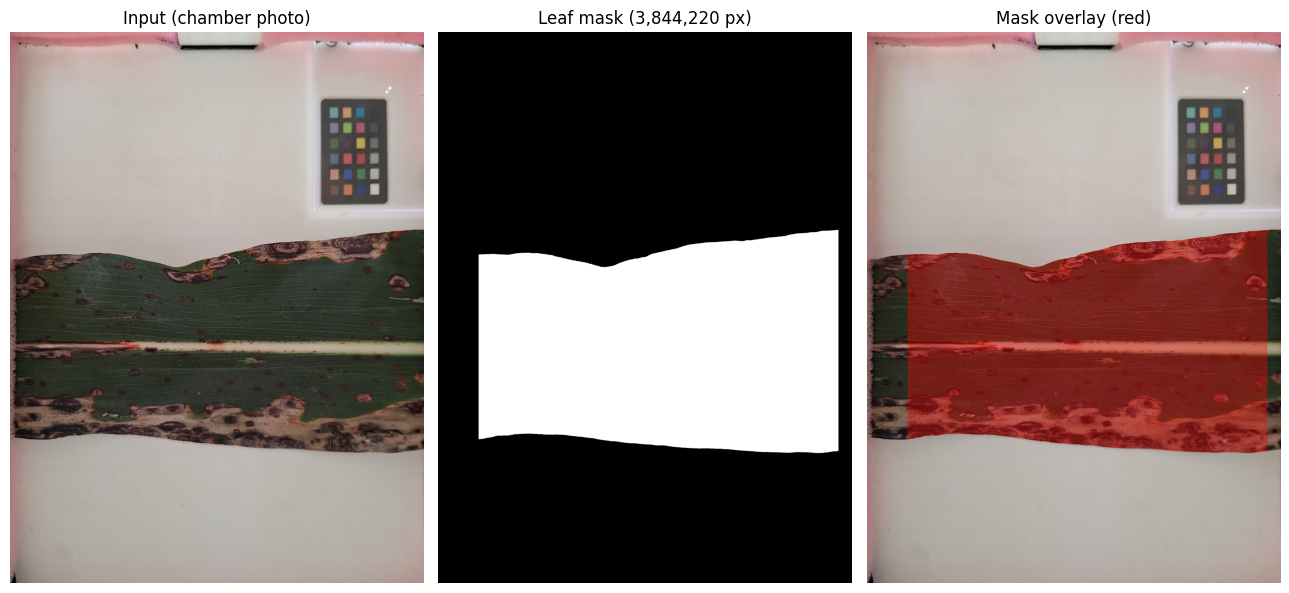

In [ ]:
seg_path = out_dir / (Path(IMG_NAME).stem + "_segmented.png")
seg_rgba = cv2.imread(str(seg_path), cv2.IMREAD_UNCHANGED)
assert seg_rgba is not None and seg_rgba.shape[2] == 4, "segmented PNG missing alpha"
mask = (seg_rgba[:, :, 3] > 0).astype(np.uint8)
mask_pixels = int(mask.sum())
valid = 750_000 <= mask_pixels <= 7_500_000
print(f"mask pixels: {mask_pixels:,} (valid range 750,000–7,500,000 -> {valid})")

overlay = rgb.copy()
overlay[mask == 1] = (0.35 * np.array([255, 0, 0]) + 0.65 * overlay[mask == 1]).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(13, 6))
axes[0].imshow(rgb); axes[0].set_title("Input (chamber photo)")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title(f"Leaf mask ({mask_pixels:,} px)")
axes[2].imshow(overlay); axes[2].set_title("Mask overlay (red)")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig("/content/mask_overlays.png", dpi=120, bbox_inches="tight")
plt.show()

### ExG vegetation index (Methods 4.6)

**English:** The paper quantifies unhealthy tissue with the normalized Excess Green index, `ExG = 2g − r − b` on RGB fractions, using the calibrated threshold **−0.0303**: leaf pixels below it are classed as diseased. We import the authors' exact `calculate_exg` from their pinned `make_exg_overlays.py` and render their ExG heatmap (normalization over leaf pixels only, background black), exactly following that script's rendering block.

**日本語:** 論文の Methods 4.6 に従い、正規化 ExG = 2g−r−b を著者コードからそのまま計算し、較正済みしきい値 −0.0303 を用いたヒートマップを描きます。

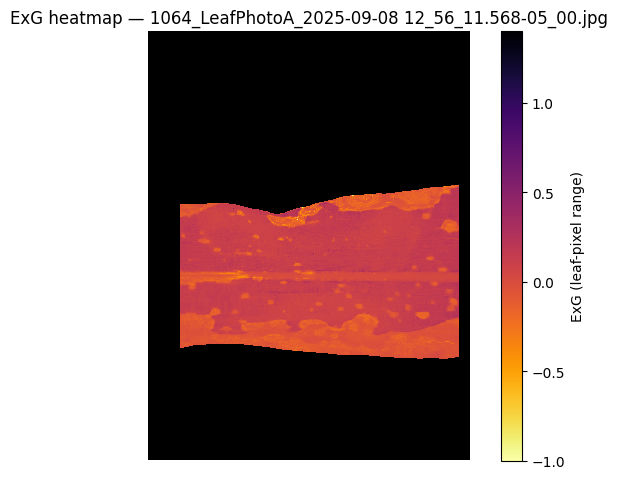

leaf pixels below ExG threshold -0.0303: 0.2677 (26.77% of 3,844,220 leaf pixels)


In [ ]:
import sys
sys.path.insert(0, str(REPO_ROOT / "figures/supplemental/FigS1_human_vi_workflows"))
from make_exg_overlays import calculate_exg  # authors' exact function (pinned commit)

EXG_P20_THRESHOLD = -0.0303  # calibrated ExG P20 cutoff (make_exg_overlays.py default)

exg_image = calculate_exg(rgb.astype(np.float32))
leaf_pixels_exg = exg_image[mask == 1].astype(np.float32)
vmin, vmax = leaf_pixels_exg.min(), leaf_pixels_exg.max()
img_norm = (exg_image.astype(np.float32) - vmin) / (vmax - vmin)  # authors' leaf-pixel normalization

cmap = plt.get_cmap("inferno_r")
img_rgba = cmap(np.clip(img_norm, 0, 1))
img_rgba[mask == 0] = [0, 0, 0, 1]

fig, ax = plt.subplots(figsize=(6.5, 4.9))
ax.imshow(img_rgba, interpolation="nearest")
sm = plt.cm.ScalarMappable(cmap="inferno_r", norm=plt.Normalize(vmin=vmin, vmax=vmax))
plt.colorbar(sm, ax=ax, label="ExG (leaf-pixel range)")
ax.set_title(f"ExG heatmap — {IMG_NAME}")
ax.axis("off")
plt.tight_layout()
plt.savefig("/content/exg_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

disease_mask = exg_image < EXG_P20_THRESHOLD
unhealthy_fraction = float(disease_mask[mask == 1].mean())
print(f"leaf pixels below ExG threshold {EXG_P20_THRESHOLD}: {unhealthy_fraction:.4f} ({unhealthy_fraction * 100:.2f}% of {mask_pixels:,} leaf pixels)")

### Disease-pixel overlay (author's blue overlay)

**English:** Following the authors' overlay block verbatim, pixels below the ExG threshold are painted pure blue and everything outside the leaf mask is removed. The left panel is the original, the right panel is the ExG-based disease overlay — this is the paper's rater-independent measurement view (Fig. S1 style), computed here from the actual sample.

**日本語:** 著者のオーバーレイ処理（ExG < しきい値を青色に）をそのまま適用し、元画像と並べて表示します。

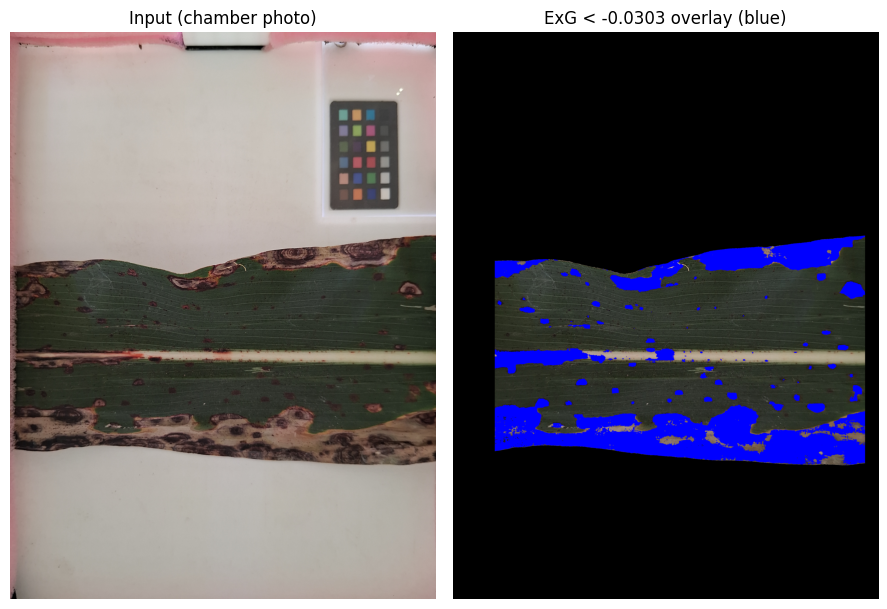

In [ ]:
overlay_rgb = rgb.astype(np.float32) / 255.0
overlay_rgb[disease_mask] = [0, 0, 1]  # pure blue (authors' exact assignment)
disease_overlay = overlay_rgb * mask[:, :, None]

fig, axes = plt.subplots(1, 2, figsize=(9, 6))
axes[0].imshow(rgb); axes[0].set_title("Input (chamber photo)")
axes[1].imshow(disease_overlay); axes[1].set_title(f"ExG < {EXG_P20_THRESHOLD} overlay (blue)")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig("/content/disease_overlay.png", dpi=120, bbox_inches="tight")
plt.show()

### Results table and CSV export

**English:** We summarize the single-image run: mask size and validity, the ExG leaf-pixel range, and the unhealthy-tissue fraction. The CSV is written inside the Colab VM (`/content/sorghum_leaf_quickstart_results.csv`) — this is one example, not a dataset-level estimate.

**日本語:** マスク面積・妥当性・ExG 範囲・病変部割合を表にまとめ、Colab 内に CSV として保存します（1 例の結果であり、データセット全体の推定ではありません）。

In [ ]:
results = pd.DataFrame([
    {"metric": "image", "value": IMG_NAME},
    {"metric": "image_shape_HxW", "value": f"{rgb.shape[0]}x{rgb.shape[1]}"},
    {"metric": "mask_pixels", "value": mask_pixels},
    {"metric": "mask_valid_750k_to_7.5M", "value": valid},
    {"metric": "exg_min_max_over_leaf", "value": f"{vmin:.4f} .. {vmax:.4f}"},
    {"metric": "exg_threshold", "value": EXG_P20_THRESHOLD},
    {"metric": "unhealthy_fraction_of_leaf", "value": round(unhealthy_fraction, 6)},
])
display(results)
results.to_csv("/content/sorghum_leaf_quickstart_results.csv", index=False)
print("wrote /content/sorghum_leaf_quickstart_results.csv")

,metric,value
0,image,1064_LeafPhotoA_2025-09-08 12_56_11.568-05_00.jpg
1,image_shape_HxW,4080x3060
2,mask_pixels,3844220
3,mask_valid_750k_to_7.5M,True
4,exg_min_max_over_leaf,-1.0000 .. 1.4000
5,exg_threshold,-0.0303
6,unhealthy_fraction_of_leaf,0.267655


wrote /content/sorghum_leaf_quickstart_results.csv


## Interpretation, differences from the paper, and validation record

**English.** This notebook executed the authors' own pinned code paths end to end on their documented example: the exact quick-start segmentation command and the exact `calculate_exg` function, with only two documented adaptations — (1) OpenCV/numpy/sklearn are Colab's preinstalled versions because the authors' `opencv-python==4.6.0.66` pin has no wheel for Colab's newer Python (the invoked APIs, `cv2.floodFill` with `FLOODFILL_FIXED_RANGE | FLOODFILL_MASK_ONLY` and `connectedComponentsWithStats`, are stable across these versions); (2) figure DPI reduced to 120 for notebook display. The ExG threshold and mask-validity window are the paper's calibrated values taken from the author code, not re-fit here.

What this does **not** show: embedding quality, random-forest prediction of human scores (ρ² 0.60–0.64), GWAS hotspots, or any population-level statistic. Those require the unreleased image collections, marker VCF, and (for SAM3) a gated checkpoint — see the paper's data-availability statements and the blocked routes recorded in the run investigation (Dryad DOI 10.5061/dryad.cfxpnvxpb returned 404 on 2026-10-19; SAM3 `facebook/sam3` requires authenticated HF access).

**解釈と制限.** 本ノートブックは著者のピン留めされたコードをそのまま実行した 1 例のデモです。埋め込み・RF・GWAS は未検証であり、公開データセットレベルの結果の検証ではありません。OpenCV 等は Colab 搭載版を使用（著者ピンは Python ≤3.10 用 wheel のため）、図の DPI を 120 に変更した点のみが適応です。

**Validation record:** executed top-to-bottom in a fresh Colab CPU runtime via the Colab CLI; per-cell outputs in this notebook are from that run. See the run report for hardware, timing, and archived execution logs.

## References

- Davis, J. M., Turkus, J., Arora, S., Cuellar-Perez, K. M., Gomez-Trejo, L. F., Ruvalcaba-Ramirez, R., Ullagaddi, C., Kuang, X., Punnuri, S., Kim, S.-B., Schnable, J. C. (2026). *Embeddings from standardized sorghum leaf images capture variation in disease response that human scoring misses.* bioRxiv 2026.09.21.753202. https://doi.org/10.64898/2026.09.21.753202
- Author code: https://github.com/jschnable/SorghumLeafEmbeddings @ `4d859d1bdc45b03a3552c4198e998fcab9cd0a2f` (CC BY 4.0) — `scripts/segment_leaf.py`, `scripts/prepare_illustrations.py`, `figures/supplemental/FigS1_human_vi_workflows/make_exg_overlays.py`, `scripts/README.md` quick start.
- Example data: `data/provided/examples/images/1064_LeafPhotoA_2025-09-08 12_56_11.568-05_00.jpg` (same commit), verified by Git blob SHA-1 `4373b827aae093f943f7df9171f75e1b4515f6e9`.
- PhenoPaper investigation `p-59663e5421b0f031f5bfb5d820418934-20261019T103528Z-618705` was used as prior research guidance (unverified lead); all scientific parameters above were confirmed against the pinned author code.